# Final Project - Lid driven cavity with obstacle

### Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.patches import FancyArrowPatch
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
from tqdm.notebook import tqdm

### Parameters (Changeable)

In [2]:
N_POINTS = 41 # Divides the box into 41x41 points
DOMAIN_SIZE = 1.0 # This defines the physical length of the "box" your fluid is in. This value is used to calculate element_length (the distance between two grid points) by dividing the size by the number of points minus one.
N_ITERATIONS = 500
TIME_STEP_LENGTH = 0.001
KINEMATIC_VISCOSITY = 0.1 # How thick or gooey the liquid is
DENSITY = 1.0 # How heavy the liquid is
HORIZONTAL_VELOCITY_TOP = 1.0

N_PRESSURE_POISSON_ITERATIONS = 50 # This is a setting for the numerical solver used to calculate fluid pressure.  
# In fluid dynamics simulations, calculating how pressure changes is often the most "expensive" part mathematically.  
# The computer doesn't solve the pressure equation perfectly in one go; instead, it "guesses" and refines that guess over multiple loops (iterations).  
# 50 means the computer will run the solver loop 50 times per time step to try to get a stable pressure value before moving to the next frame of the animation.
STABILITY_SAFETY_FACTOR = 0.5 # To prevent the simulation from crashing.
# Numerical simulations can become unstable (values shoot up to infinity) if the TIME_STEP_LENGTH is too large relative to the viscosity and grid size.  
# The code calculates a maximum_possible_time_step_length based on physics theory.  
# By setting the safety factor to 0.5, you are telling the program: "Only let the user run this if their time step is half of what the math says is technically allowed".  
# If the TIME_STEP_LENGTH exceeds this "safe" zone, the code will trigger a RuntimeError stating that stability is not guaranteed.

OBSTACLE_X = 0.40
OBSTACLE_Y = 0.40
OBSTACLE_WIDTH = 0.20
OBSTACLE_HEIGHT = 0.20

SAVE_EVERY = 10

### Helper functions

In [3]:
def central_difference_x(f, element_length):
    """
    To find the change in speed at a specific point, 
    the code looks at the point to the right and the point to the left, subtracts them, and divides by the distance. 
    It's like finding the "slope" of the water speed.

    f: a 2D NumPy array
    """
    diff = np.zeros_like(f) # The NumPy function numpy.zeros_like() returns a new array of zeros that has the exact same shape and data type as a prototype array you provide.
    diff[1:-1, 1:-1] = (f[1:-1, 2:] - f[1:-1, 0:-2]) / (2 * element_length)
    # The Interior: 1:-1 selects everything except the first and last elements. The function only calculates the slope for points that actually have neighbors on both sides.
    # The thing is [y, x] or [row, column]
    return diff

def central_difference_y(f, element_length):
    """
    To find the change in speed at a specific point, 
    the code looks at the point to the bottom and the point to the top, subtracts them, and divides by the distance. 
    It's like finding the "slope" of the water speed.

    f: a 2D NumPy array
    element_length: represents the physical distance between any two adjacent points on the simulation grid.
    """
    diff = np.zeros_like(f)
    diff[1:-1, 1:-1] = (f[2:, 1:-1] - f[0:-2, 1:-1]) / (2 * element_length)
    return diff

def laplace(f, element_length):
    """
    This is used for pressure. 
    It looks at all four neighbors (Up, Down, Left, Right) to see how "squeezed" the water is at that point.
    If the center point is much faster than its neighbors, the result is negative, indicating that viscosity will slow that point down in the next step.

    f: a 2D NumPy array
    element_length: represents the physical distance between any two adjacent points on the simulation grid.
    """
    diff = np.zeros_like(f)
    diff[1:-1, 1:-1] = (
        f[1:-1, 0:-2]   # left neighbor
        + f[0:-2, 1:-1] # top neighbor
        + f[1:-1, 2:]   # right neighbor
        + f[2:, 1:-1]   # bottom neighbor
        - 4 * f[1:-1, 1:-1] # Laplacian as a measure of "How different am I from the average of my neighbors?"
    ) / (element_length**2) 
    return diff

def apply_solid_bc(u, v, solid):
    """
    This stands for Boundary Conditions. 
    It says: "If a grid point is inside the obstacle, its velocity must be 0." 
    Water can't move through a solid block.

    u: horizontal velocity, a 2D NumPy array
    v: vertical velocity, a 2D NumPy array
    solid: solid is a 2D NumPy array of the same shape as u and v, but instead of numbers, it contains Booleans (True or False):  
        False: Means that specific grid point is fluid (water can flow here).  
        True: Means that specific grid point is part of the obstacle (a wall).
    """
    u[solid] = 0.0
    v[solid] = 0.0
    return u, v

### Grid obstacle and setup

In [4]:
element_length = DOMAIN_SIZE / (N_POINTS - 1)
# DOMAIN_SIZE: The total length of one side of the box (set to 1.0).  
# N_POINTS - 1: The number of gaps (intervals) between your grid points.  
# If the box is 1 meter wide and you have 41 points, there's 40 gaps, making each element_length exactly 0.025 units.

x = np.linspace(0.0, DOMAIN_SIZE, N_POINTS) # np.linspace() function in NumPy is used to create an array of evenly spaced numbers over a specified interval. Unlike np.arange(), which requires you to specify a step size, np.linspace() lets you specify exactly how many values you want.
y = np.linspace(0.0, DOMAIN_SIZE, N_POINTS)
X, Y = np.meshgrid(x, y) # np.meshgrid is a function in Python's NumPy library used to create a rectangular grid from two or more 1D arrays

u_prev = np.zeros_like(X)
v_prev = np.zeros_like(X)
p_prev = np.zeros_like(X)

# ============== Setting up the obstacle ==============
solid = np.zeros_like(X, dtype=bool) # Making the blank grid obstacle

# x0, y0, x1, y1: These are physical coordinates (floating-point numbers)
x0 = OBSTACLE_X
y0 = OBSTACLE_Y
x1 = OBSTACLE_X + OBSTACLE_WIDTH
y1 = OBSTACLE_Y + OBSTACLE_HEIGHT

# i0, j0, i1, j1: These are array indices (integers). Arrays don't understand "0.4 meters"; they only understand positions like "index 16" or "index 17."
i0 = np.argmin(np.abs(x - x0)) # np.argmin() returns the indices of the minimum values along a specified axis. Instead of giving the smallest number itself (which np.min() does), it tells exactly where that number is located in the array.
j0 = np.argmin(np.abs(y - y0))
i1 = np.argmin(np.abs(x - x1))
j1 = np.argmin(np.abs(y - y1))

solid[j0:j1+1, i0:i1+1] = True # Defining a 2D array of booleans. If a coordinate is True, it’s a "wall."

# these variables are used to determine the exact physical dimensions of the obstacle as it appears on the computational grid.
# Why are these needed? The simulation math uses the solid boolean array (based on indices), but the animation and plotting functions (like matplotlib.patches.Rectangle) need real-world coordinates to draw the box on your screen.  
# Using these _plot values ensures that the red box you see in the animation perfectly covers the area where the water velocity is being forced to zero
x0_plot = x[i0] # bottom left coordinate (X)
y0_plot = y[j0] # bottom left coordinate (Y)
width_plot = x[i1] - x[i0]  # true physical width of the obstacle in the simulation by measuring the distance between the two chosen grid points on the x-axis.
height_plot = y[j1] - y[j0] # true physical height of the obstacle in the simulation by measuring the distance between the two chosen grid points on the y-axis.
# =====================================================

# Safety check to prevent the simulation from "exploding" mathematically.
maximum_possible_time_step_length = 0.5 * element_length**2 / KINEMATIC_VISCOSITY
if TIME_STEP_LENGTH > STABILITY_SAFETY_FACTOR * maximum_possible_time_step_length:
    raise RuntimeError("Stability is not guaranteed")

### Animation

In [5]:
frames = []

frames.append({
    "iteration": 0,
    "time": 0.0,
    "u": u_prev.copy(),
    "v": v_prev.copy(),
    "p": p_prev.copy()
})

for iteration in tqdm(range(1, N_ITERATIONS + 1)):
    # These values are used immediately after they are calculated to find the Advection (how the fluid pushes itself around).
    d_u_prev__d_x = central_difference_x(u_prev, element_length) # ∂u/∂x As you move horizontally, how much does the horizontal speed change?
    d_u_prev__d_y = central_difference_y(u_prev, element_length) # ∂u/∂y As you move vertically, how much does the horizontal speed change?
    d_v_prev__d_x = central_difference_x(v_prev, element_length) # ∂v/∂x As you move horizontally, how much does the vertical speed change?
    d_v_prev__d_y = central_difference_y(v_prev, element_length) # ∂v/∂y As you move vertically, how much does the vertical speed change?

    # The Laplacian tells the computer how the "thick or gooey" nature of the liquid (KINEMATIC_VISCOSITY) should cause fast-moving fluid to slow down and pull slow-moving fluid along with it.
    laplace__u_prev = laplace(u_prev, element_length) # Smooths out horizontal speed differences
    laplace__v_prev = laplace(v_prev, element_length) # Smooths out vertical speed differences

    # tent means tentative.
    # The computer makes a "guess" at the new velocity by only looking at momentum and viscosity.
    # This guess is "tentative" because it usually violates the rules of a liquid—it might look like the water is bunching up or disappearing at certain points.
    u_tent = (
        u_prev
        + TIME_STEP_LENGTH * (
            -(u_prev * d_u_prev__d_x + v_prev * d_u_prev__d_y) # Advection term. Represents fluid carrying itself. Advection adds the swirls and movement.
            + KINEMATIC_VISCOSITY * laplace__u_prev # Diffusion term. Represents the goopiness of the fluid. High viscosity (KINEMATIC_VISCOSITY) makes this effect stronger, acting like internal friction that resists sharp changes in speed.
        ) # u_prev + TIME_STEP_LENGTH * (...): Euler integration. computer takes the current speed (u_prev) and adds the "change in speed" (the terms in the parentheses) multiplied by how much time has passed (TIME_STEP_LENGTH).
    )

    v_tent = (
        v_prev
        + TIME_STEP_LENGTH * (
            -(u_prev * d_v_prev__d_x + v_prev * d_v_prev__d_y)
            + KINEMATIC_VISCOSITY * laplace__v_prev
        )
    )

    # Box setup of original lid driven cavity. Only the lid slides horizontally.
    u_tent[0, :] = 0.0
    u_tent[:, 0] = 0.0
    u_tent[:, -1] = 0.0
    u_tent[-1, :] = HORIZONTAL_VELOCITY_TOP

    v_tent[0, :] = 0.0
    v_tent[:, 0] = 0.0
    v_tent[:, -1] = 0.0
    v_tent[-1, :] = 0.0

    # Apply solid boundary conditions
    u_tent, v_tent = apply_solid_bc(u_tent, v_tent, solid)

    # Calculate the Divergence of the fluid.
        # Positive Divergence: Everyone is suddenly running away from the center. The area is thinning out.  
        # Negative Divergence (Convergence): Everyone is rushing toward the center. The area is becoming a "mosh pit".
        # Zero Divergence: The number of people entering a space equals the number of people leaving it. This is how incompressible fluids (like water) behave—you can't squeeze more water into a cup that is already full.
    d_u_tent__d_x = central_difference_x(u_tent, element_length) # How much the horizontal speed changes as you move left-to-right.
    d_v_tent__d_y = central_difference_y(v_tent, element_length) # How much the vertical speed changes as you move bottom-to-top.

    # rhs: right hand side
    # The Goal: You want the fluid to be incompressible (zero bunching).  
    # The Reality: Your u_tent and v_tent guesses created bunching.
    # The Math: rhs calculates exactly how much pressure is needed at every single point on the grid to "push back" against that bunching and restore balance.
    rhs = DENSITY / TIME_STEP_LENGTH * (d_u_tent__d_x + d_v_tent__d_y)

    # Because every point on the grid affects its neighbors, the computer can't find the perfect pressure field in one go. 
    # Instead, it uses an iterative solver (a "guess and check" loop) that runs for N_PRESSURE_POISSON_ITERATIONS (50 times in your case).
    for _ in range(N_PRESSURE_POISSON_ITERATIONS):
        # For every point, the code:
        # Averages its neighbors: It looks at the pressure of the four surrounding points.  
        # Adjusts for bunching: it subtracts the rhs value for that spot.  
        # Refines: It repeats this 50 times until the pressure values across the whole 41x41 grid become stable.
        p_next = np.zeros_like(p_prev)
        p_next[1:-1, 1:-1] = 0.25 * (
            p_prev[1:-1, 0:-2] # left
            + p_prev[0:-2, 1:-1] # top
            + p_prev[1:-1, 2:] # right
            + p_prev[2:, 1:-1] # bottom
            - element_length**2 * rhs[1:-1, 1:-1]
        )

        # The Box Walls (Neumann & Dirichlet Conditions) in [Y, X]
        # Neumann
        # This tells the computer that the pressure at the wall is the same as the pressure just inside the wall.
        # This ensures that fluid is neither forced into the wall nor sucked out of it, effectively acting as a solid barrier where the change in pressure is zero. 
        p_next[:, -1] = p_next[:, -2] # right wall
        p_next[0, :] = p_next[1, :] # bottom wall
        p_next[:, 0] = p_next[:, 1] # left wall
        # Dirichlet
        p_next[-1, :] = 0.0 # Fixed pressure (Dirichlet Boundary) top wall

        p_next[solid] = p_prev[solid] # The solid obstacle
        p_prev = p_next # Because the Poisson equation is being solved iteratively (the computer is "guessing and refining"), it takes the newly calculated pressure field (p_next) and sets it as the starting point (p_prev) for the next of the 50 iterations.

    # Pressure field (p_next)
    d_p_next__d_x = central_difference_x(p_next, element_length) # ∂p/∂x Measures how the pressure changes as you move horizontally across the grid.
    d_p_next__d_y = central_difference_y(p_next, element_length) # ∂p/∂y Measures how the pressure changes as you move vertically up the grid.

    # Velocity correction. The code uses the pressure gradient (the slopes you just calculated) to nudge the tentative velocities.
    # It takes the tentative velocity (u_tent) and subtracts the pressure slope (d_p_next__d_x).
        # TIME_STEP_LENGTH / DENSITY acts as a scaling factor. A heavier fluid (DENSITY) is harder to push, so the pressure nudge has a smaller effect.
    u_next = u_tent - TIME_STEP_LENGTH / DENSITY * d_p_next__d_x
    v_next = v_tent - TIME_STEP_LENGTH / DENSITY * d_p_next__d_y

    # ============== Error analysis ==============
    # Calculate the slopes of the final corrected velocities
    d_u_final__d_x = central_difference_x(u_next, element_length)
    d_v_final__d_y = central_difference_y(v_next, element_length)
    
    # Measure the divergence (should be zero in a perfect simulation)
    divergence = d_u_final__d_x + d_v_final__d_y
    
    # Calculate the L2-norm residual (root mean square of the error)
    # We only look at the interior [1:-1, 1:-1] where the math was applied
    residual = np.sqrt(np.mean(divergence[1:-1, 1:-1]**2))
    
    # Save the error data for later plotting
    if 'errors' not in locals(): errors = []
    errors.append(residual)
    # ============================================

    # ============== Re-applying solid boundaries ==============
    # Why? The pressure correction step nudges every point on the grid. This nudge might accidentally give a small amount of speed to the points inside your solid obstacle.
    u_next, v_next = apply_solid_bc(u_next, v_next, solid)

    # While the simulation loop does calculate how water moves in the center, the math (especially the pressure correction step) can sometimes "smear" values onto the edges.
    # If you didn't force these back to specific values, your walls would eventually start "leaking" speed, and the whole simulation would fall apart.  
    # Ensure that the bottom, left, and right sides of the box act as solid, unmoving boundaries where the velocity is exactly 0.0
    u_next[0, :] = 0.0
    u_next[:, 0] = 0.0
    u_next[:, -1] = 0.0
    u_next[-1, :] = HORIZONTAL_VELOCITY_TOP

    v_next[0, :] = 0.0
    v_next[:, 0] = 0.0
    v_next[:, -1] = 0.0
    v_next[-1, :] = 0.0
    # ==========================================================

    # Save the animation every 10 frames
    if iteration % SAVE_EVERY == 0 or iteration == N_ITERATIONS:
        frames.append({
            "iteration": iteration,
            "time": iteration * TIME_STEP_LENGTH,
            "u": u_next.copy(),
            "v": v_next.copy(),
            "p": p_next.copy()
        })

    u_prev = u_next
    v_prev = v_next
    p_prev = p_next

plt.style.use("dark_background")

# fig: figure. The entire blank canvas or the window itself. it manages the overall display, background, and saving of the image.
# ax: axes. This is the actual individual plot inside the figure. This is where the fluid arrows (quiver plot), pressure contours, and obstacle box are actually drawn.
fig, ax = plt.subplots(figsize=(6, 6))

frame0 = frames[0] # This retrieves the first dictionary object stored in your frames list.
u0 = frame0["u"].copy() # These lines pull the horizontal (u) and vertical (v) velocity arrays for that specific frame.
v0 = frame0["v"].copy() 
speed0 = np.sqrt(u0**2 + v0**2) # This calculates the magnitude of the velocity at every single grid point. Since velocity is a vector (it has a direction), you use the Pythagorean theorem (a^2 + b^2 = c^2) to find the total speed regardless of which way the water is moving.

speed0[solid] = np.nan # The Logic: solid is the boolean mask that identifies grid points inside the obstacle. By setting those specific points to np.nan (Not a Number), you are telling the plotting tool: "There is no speed here to draw".
img = ax.imshow( # This function draws a 2D image based on the values in an array.
    speed0,
    extent=[0, 1, 0, 1],
    origin="lower",
    cmap="coolwarm",
    vmin=0,
    vmax=HORIZONTAL_VELOCITY_TOP,
    animated=False
)

fig.colorbar(img, ax=ax)

rect = patches.Rectangle(
    (x0_plot, y0_plot),
    width_plot,
    height_plot,
    linewidth=2,
    edgecolor="black",
    facecolor="gray",
    alpha=0.6,
    zorder=10
)
ax.add_patch(rect)

title = ax.set_title("")
ax.set_xlim(0, DOMAIN_SIZE)
ax.set_ylim(0, DOMAIN_SIZE)

stream = None # At the start, no streamlines exist yet, so stream is initialized to None.

def remove_old_stream_artists(ax, stream):
    if stream is not None:
        stream.lines.remove()

    # streamplot arrowheads are FancyArrowPatch objects living in ax.patches
    for artist in list(ax.patches):
        if isinstance(artist, FancyArrowPatch):
            artist.remove()

def init():
    title.set_text("")
    return img, title

def update(i):
    global stream

    frame = frames[i]
    u = frame["u"].copy()
    v = frame["v"].copy()
    speed = np.sqrt(u**2 + v**2)

    speed[solid] = np.nan
    img.set_array(speed)

    remove_old_stream_artists(ax, stream)

    u_masked = np.ma.array(u, mask=solid)
    v_masked = np.ma.array(v, mask=solid)

    stream = ax.streamplot(
        X, Y,
        u_masked, v_masked,
        color="black",
        density=1.2
    )

    title.set_text(f"Iteration = {frame['iteration']}, time = {frame['time']:.3f} s")
    return img, title

ani = FuncAnimation(
    fig,
    update,
    frames=len(frames),
    init_func=init,
    interval=100,
    blit=False
)

plt.close(fig)
HTML(ani.to_jshtml())

  0%|          | 0/500 [00:00<?, ?it/s]

### Error analysis

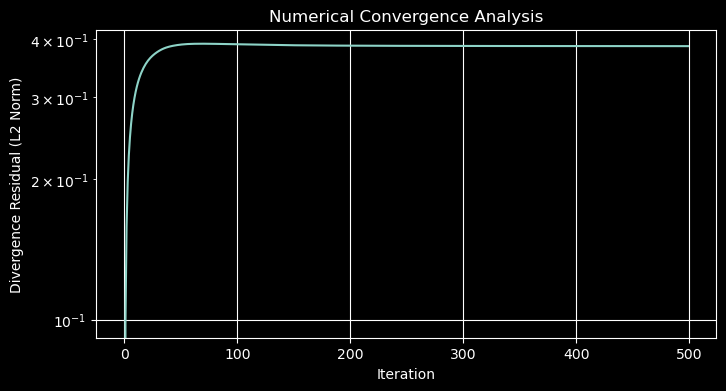

In [6]:
plt.figure(figsize=(8, 4))
plt.plot(errors)
plt.yscale('log') # Error usually drops by orders of magnitude
plt.xlabel('Iteration')
plt.ylabel('Divergence Residual (L2 Norm)')
plt.title('Numerical Convergence Analysis')
plt.grid(True)
plt.show()